# 01 · Vibration feature extraction

Runs the `_02` feature path (`ProBallast_dataGen` + acceptance QC) on real
`W10v140` logs. Tweak `cfg` to experiment with the frequency range, QC
thresholds, changepoint penalty, etc.


In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
from intelliswitch import Config, paths

# --- paths -----------------------------------------------------------------
# The project data lake (medallion tiers) is resolved by intelliswitch.paths, so
# it works regardless of the notebook's working dir and is overridable via the
# INTELLISWITCH_DATA_DIR / INTELLISWITCH_MODELS_DIR env vars.
RAW_CACHE = paths.RAW_CACHE       # data/interim/raw_cache  (decoded .npz, stage 1)
STORE     = paths.FEATURE_STORE   # data/processed/feature_store
MODELS    = paths.MODELS          # data/models
paths.ensure()                    # create the lake dirs if missing

# Raw source recordings (~7,800 logs) are large and live on the external drive;
# point DATA_ROOT at them, or symlink/copy the source into paths.RAW.
DATA_ROOT = Path(r"/Volumes/Seagate Expansion Drive/Mohammad/M Drive DTU/MATLAB Scripts/IntelliswitchScripts")
W10   = DATA_ROOT / "W10v140"       # vibration .log
BLADE = DATA_ROOT / "Bladenr8252"   # geometry .csv

cfg = Config()
cfg.freq_min_hz, cfg.freq_max_hz, cfg.geom_method, cfg.geom_sensor_locations_m

(10.0, 1000.0, 'std', (4.0, 9.0, 37.0, 50.0))

In [2]:
from pathlib import Path
from intelliswitch.features import extract_features

logs = sorted(Path(W10).glob('*.log'))[:15]
rows = []
for p in logs:
    r = extract_features(p, cfg)
    tag = f'OK rows={len(r.features)}' if r.accepted else f'skip ({r.reason})'
    v = f'{r.geom.speed_kmh:6.1f}' if r.geom else '   n/a'
    print(f'{p.name:24s} v={v} km/h  {tag}')
    if r.accepted:
        rows.append(r.features)
feat = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
feat.shape


160713_183814.log        v= 138.1 km/h  skip (n_groups 4 != required 5)
160714_123907.log        v= 159.1 km/h  skip (no accepted wheel-groups)
160714_143804.log        v= 136.4 km/h  skip (n_groups 4 != required 5)
160714_151419.log        v= 140.7 km/h  OK rows=1
160714_234644.log        v= 141.0 km/h  OK rows=1
160715_002057.log        v= 160.3 km/h  skip (no accepted wheel-groups)
160715_012329.log        v= 140.5 km/h  OK rows=6
160715_023554.log        v= 160.5 km/h  skip (no accepted wheel-groups)
160715_113821.log        v= 138.5 km/h  skip (n_groups 4 != required 5)
160715_151412.log        v= 156.4 km/h  OK rows=1
160715_171515.log        v= 160.5 km/h  skip (no accepted wheel-groups)
160715_193803.log        v= 135.1 km/h  skip (n_groups 4 != required 5)
160715_234948.log        v= 155.0 km/h  OK rows=2
160716_002007.log        v= 161.1 km/h  skip (no accepted wheel-groups)
160716_012210.log        v= 139.4 km/h  skip (n_groups 4 != required 5)


(11, 1001)

### Inspect one PSD feature vector


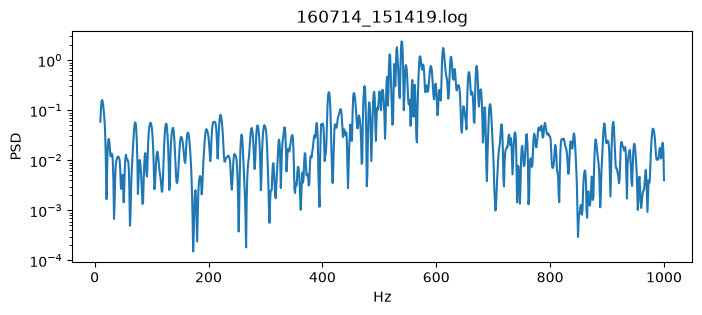

In [3]:
import matplotlib.pyplot as plt
grid = cfg.freq_grid
fcols = [c for c in feat.columns if c.startswith('f')]
p = feat.iloc[0][fcols].to_numpy(float)
plt.figure(figsize=(8,3))
plt.semilogy(grid, p)
plt.xlabel('Hz'); plt.ylabel('PSD'); plt.title(feat.iloc[0]['source']); plt.show()
